<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A08_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

**Виконав:** Точенюк Ярослав, група 4-9.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

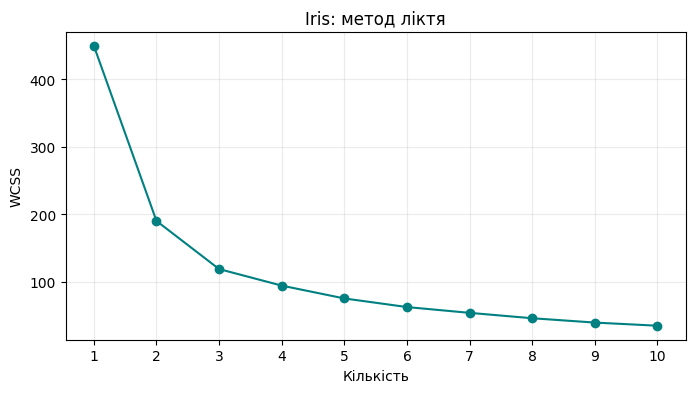

In [3]:
features = iris_df.columns[:3].tolist()
Xi = StandardScaler().fit_transform(iris_df[features])
ks = list(range(1, 11))
def inertia_curve(X):
    return [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in ks]
def curve(x, y, title, ylabel):
    plt.figure(figsize=(8,4)); plt.plot(x,y,'o-',color='teal'); plt.xticks(x); plt.xlabel('Кількість'); plt.ylabel(ylabel); plt.title(title); plt.grid(alpha=.25); plt.show()
wi = inertia_curve(Xi)
curve(ks,wi,'Iris: метод ліктя','WCSS')

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

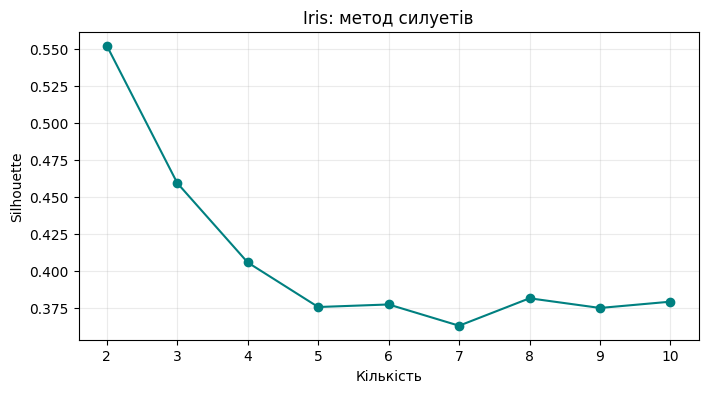

Максимум силуета: 2


In [4]:
def silhouettes(X):
    return [silhouette_score(X,KMeans(n_clusters=k,random_state=42,n_init=10).fit_predict(X)) for k in range(2,11)]
si = silhouettes(Xi)
curve(list(range(2,11)),si,'Iris: метод силуетів','Silhouette')
print('Максимум силуета:', 2+int(__import__('numpy').argmax(si)))

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

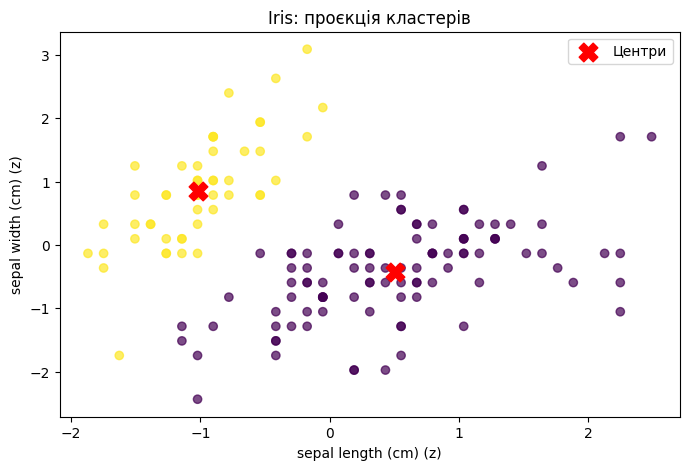

WCSS: [450.0, 190.47, 119.14, 94.64, 75.63, 62.87, 54.28, 46.31, 39.89, 35.23]
Силуети: [np.float64(0.552), np.float64(0.459), np.float64(0.406), np.float64(0.375), np.float64(0.377), np.float64(0.363), np.float64(0.381), np.float64(0.375), np.float64(0.379)]


In [5]:
km = KMeans(n_clusters=2,random_state=42,n_init=10).fit(Xi)
plt.figure(figsize=(8,5)); plt.scatter(Xi[:,0],Xi[:,1],c=km.labels_,cmap='viridis',alpha=.7); plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],marker='X',s=180,c='red',label='Центри'); plt.xlabel(features[0]+' (z)'); plt.ylabel(features[1]+' (z)'); plt.legend(); plt.title('Iris: проєкція кластерів'); plt.show()
print('WCSS:', [round(v,2) for v in wi]); print('Силуети:', [round(v,3) for v in si])

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Два кластери задані умовою; максимум силуета та WCSS виводяться вище. Метод ліктя оцінює спад WCSS, а силует — компактність та відокремленість груп.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import os, sys, subprocess, importlib.util
from pathlib import Path
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
candidates = [Path('Student_data.csv'), Path('Student_performance_data _.csv')]
csv_file = next((p for p in candidates if p.is_file()), None)
if csv_file is None:
    if importlib.util.find_spec('kagglehub') is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q','kagglehub'])
    import kagglehub
    path = Path(kagglehub.dataset_download('rabieelkharoua/students-performance-dataset'))
    csv_file = next((p for p in path.rglob('*.csv') if 'student' in p.name.lower()), None)
    if csv_file is None:
        raise FileNotFoundError('Завантажте Student_data.csv у робочу папку.')
print('Файл:', csv_file)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Файл: /kaggle/input/students-performance-dataset/Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()
display(df.head())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
display(df.isna().sum().to_frame("Пропуски"))

,Пропуски
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Дублікати:", df.duplicated().sum())

Дублікати: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
display(df.describe(include="all"))

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
clean = df.drop_duplicates().dropna(subset=['GradeClass']).copy()
X = clean.drop(columns=['GradeClass','StudentID']); y = clean['GradeClass']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
results = {}; fitted = {}
print(X_train.shape, X_test.shape)

(1913, 13) (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
def fit_model(name, model, params):
    pipeline = Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',model)])
    search = GridSearchCV(pipeline,params,cv=cv,scoring='accuracy',n_jobs=2,error_score='raise')
    search.fit(X_train,y_train)
    accuracy = accuracy_score(y_test,search.predict(X_test))
    results[name] = {'CV accuracy':search.best_score_,'Test accuracy':accuracy}; fitted[name]=search
    print('Параметри:',search.best_params_); print('CV:',search.best_score_,'Test:',accuracy)
fit_model('Random Forest',RandomForestClassifier(random_state=42,n_jobs=1),{'model__n_estimators':[100,200],'model__max_depth':[None,8,16],'model__min_samples_leaf':[1,3]})

Параметри: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
CV: 0.9205377769879568 Test: 0.9123173277661796


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
fit_model('Logistic Regression',LogisticRegression(solver='saga',max_iter=5000,random_state=42),{'model__C':[.01,.1,1,10],'model__penalty':['l1','l2']})

Параметри: {'model__C': 0.1, 'model__penalty': 'l1'}
CV: 0.8102401815373259 Test: 0.8183716075156576


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
fit_model('SVM',SVC(),{'model__C':[.1,1,10],'model__kernel':['linear','rbf'],'model__gamma':['scale']})

Параметри: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
CV: 0.8536259620247973 Test: 0.8580375782881002


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

,CV accuracy,Test accuracy
Random Forest,0.920538,0.912317
Logistic Regression,0.810240,0.818372
SVM,0.853626,0.858038


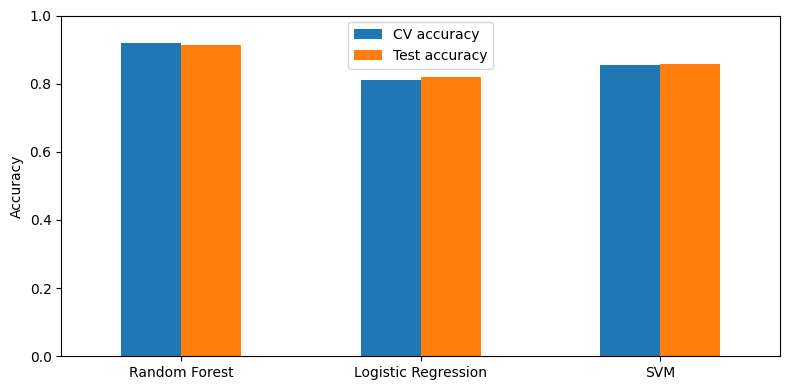

Найкраща за CV: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.87      0.85        54
         2.0       0.90      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.92      0.91      0.90       479



In [18]:
comparison = pd.DataFrame(results).T
best = comparison['CV accuracy'].idxmax()
display(comparison); comparison.plot.bar(figsize=(8,4),rot=0); plt.ylim(0,1); plt.ylabel('Accuracy'); plt.tight_layout(); plt.show()
print('Найкраща за CV:',best)
print(classification_report(y_test,fitted[best].predict(X_test),zero_division=0))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

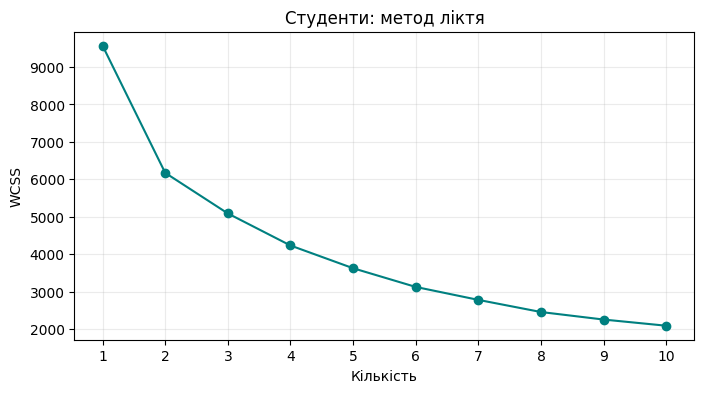

In [19]:
student_features = ['Age','StudyTimeWeekly','Absences','GPA']
Xs = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(clean[student_features]))
ws = inertia_curve(Xs)
curve(ks,ws,'Студенти: метод ліктя','WCSS')

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

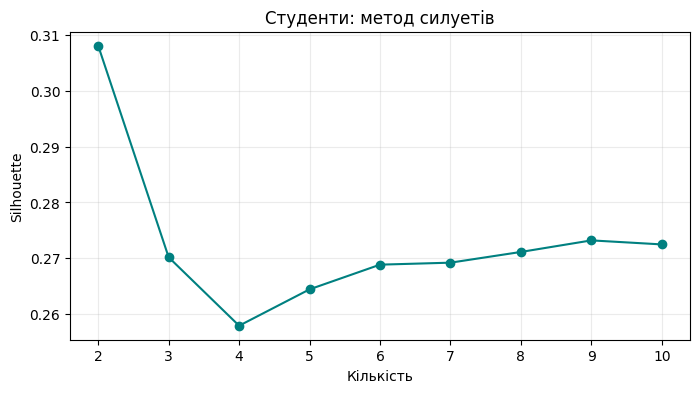

Оптимум за силуетом: 2


In [20]:
ss = silhouettes(Xs)
curve(list(range(2,11)),ss,'Студенти: метод силуетів','Silhouette')
print('Оптимум за силуетом:',2+np.argmax(ss))

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
for package in ['kneed','yellowbrick']:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',package])

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all = clean.drop(columns=['StudentID','GradeClass'])
print(X_all.columns.tolist())

['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
Xp = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X_all))
pca = PCA().fit(Xp)
ratios = pca.explained_variance_ratio_
components = np.arange(1,len(ratios)+1)
print(ratios)

[0.15246911 0.0861136  0.08267885 0.08071826 0.07864825 0.07793075
 0.0763079  0.07600434 0.07440892 0.0737979  0.07167781 0.06746103
 0.00178329]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

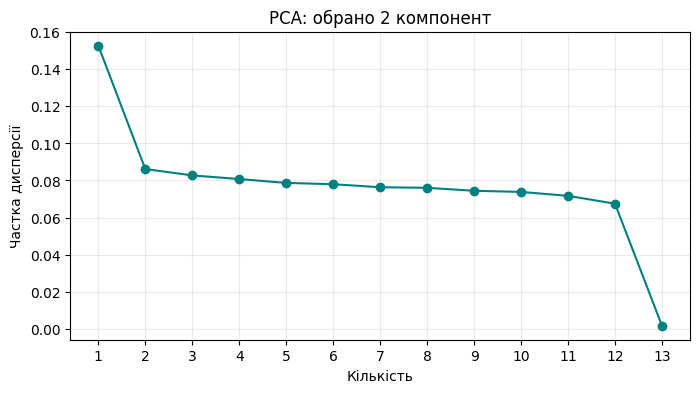

Лікоть: 2 ; обрано: 2


In [25]:
knee = KneeLocator(components,ratios,curve='convex',direction='decreasing').knee
n_components = int(knee) if knee is not None else int(np.searchsorted(np.cumsum(ratios),.8)+1)
curve(components,ratios,f'PCA: обрано {n_components} компонент','Частка дисперсії')
print('Лікоть:',knee,'; обрано:',n_components)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

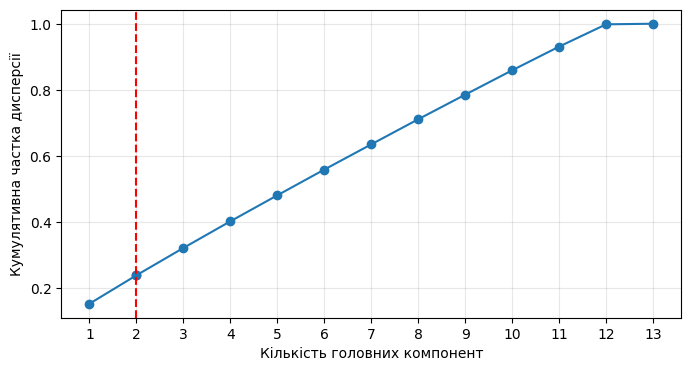

Пояснена дисперсія: 23.86%


In [26]:
cumulative = np.cumsum(ratios)
explained = cumulative[n_components-1]
plt.figure(figsize=(8,4)); plt.plot(components,cumulative,'o-'); plt.axvline(n_components,color='red',ls='--'); plt.scatter([n_components],[explained],color='red'); plt.xticks(components); plt.xlabel('Кількість головних компонент'); plt.ylabel('Кумулятивна частка дисперсії'); plt.grid(alpha=.3); plt.show()
print(f'Пояснена дисперсія: {explained:.2%}')
X_pca = PCA(n_components=n_components).fit_transform(Xp)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

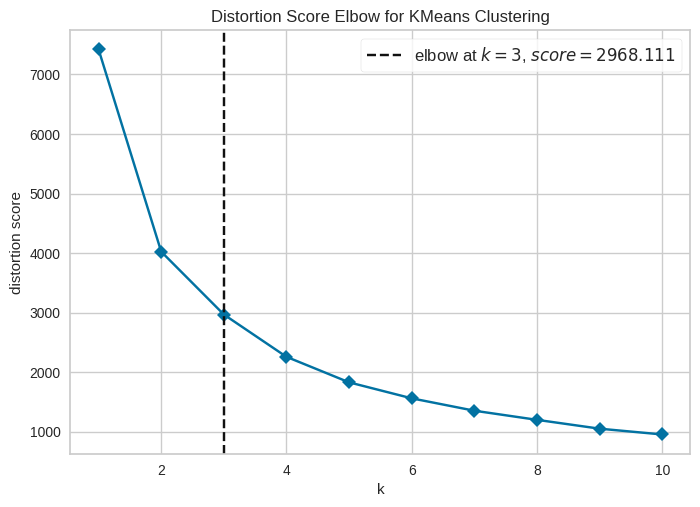

Лікоть після PCA: 3
Студенти: лікоть=4, силует=2; після PCA лікоть=3.
Класифікація прогнозує GradeClass; найкраща CV-модель: Random Forest. Кластеризація не використовує GradeClass і групує схожі спостереження. PCA: 2 компонент, 23.86% дисперсії.


In [28]:
visualizer = KElbowVisualizer(KMeans(random_state=42,n_init=10),k=(1,11),timings=False)
visualizer.fit(X_pca); visualizer.show()
print('Лікоть після PCA:',visualizer.elbow_value_)
# Порівняння ліктя та силуетів на початкових ознаках студентів.
student_elbow = KneeLocator(ks,ws,curve='convex',direction='decreasing').knee
print(f'Студенти: лікоть={student_elbow}, силует={2+np.argmax(ss)}; після PCA лікоть={visualizer.elbow_value_}.')
print(f'Класифікація прогнозує GradeClass; найкраща CV-модель: {best}. Кластеризація не використовує GradeClass і групує схожі спостереження. PCA: {n_components} компонент, {explained:.2%} дисперсії.')

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Числові висновки автоматично виводяться в останній програмній комірці. Класифікація використовує відомі мітки, кластеризація — ні.